# Q004: Orthogonal Quantum Krylov Diagonalisation (OQKD)

## Problem
Quantum Krylov diagonalisation (QKD) estimates a ground-state energy from a small set of states built by applying the Hamiltonian over and over to a starting state |Φ₀⟩. These states become nearly parallel, so the **overlap matrix S becomes ill-conditioned**. The usual fix is *thresholding* (discarding small overlap eigenvalues), which slows convergence.

Rammal *et al.* ([arXiv:2607.09476](https://arxiv.org/abs/2607.09476)) propose **OQKD**, which carries out the classical Lanczos recursion on *polynomials* Pₙ(H). Each basis state Pₙ(H)|Φ₀⟩ is orthogonal by construction and only ⟨H⟩ and ⟨H²⟩ have to be measured, so the projected Hamiltonian is tridiagonal and S = I.

**Tasks.** For the frustrated J₁–J₂ Heisenberg chain (12 qubits, J₂/J₁ = 0.5), starting from the Néel (mean-field) state:
1. Show how cond(S) grows for power-basis QKD and Chebyshev QKD (CQKD), and how thresholding affects convergence.
2. Implement OQKD as a polynomial-coefficient recursion and check that it stays orthogonal and converges like exact Lanczos.
3. Find the **hidden cost**: on hardware, P(H) is applied by block encoding with a success probability of about 1/max|P(x)|². How does this scale?
4. Test the **restarted** protocol and the effect of **shot noise** on the measured ⟨H⟩ and ⟨H²⟩.

*Emulation note:* the T_k(H)|ψ⟩ states that block encoding + GQSP would prepare on hardware are computed exactly here with sparse matrices. Everything the algorithm *uses* is still only what a device could measure.

In [1]:
!pip install -q qiskit

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from numpy.polynomial import chebyshev as C
from qiskit.quantum_info import SparsePauliOp
%matplotlib inline

## 1. The J₁–J₂ Heisenberg chain
H = Σᵢ J₁ **σ**ᵢ·**σ**ᵢ₊₁ + J₂ **σ**ᵢ·**σ**ᵢ₊₂ (Pauli operators, open chain). At J₂/J₁ = 0.5 this is the Majumdar–Ghosh point, where the exact ground-state energy is −3N/2 = −18, a handy check.

Block-encoding methods need the spectrum inside [−1, 1]. We use a **tight** shift-and-scale so the spectrum fills that interval. Section 5 shows why this matters.

In [3]:
N = 12                     # qubits (spins)
J1, J2 = 1.0, 0.5          # nearest and next-nearest neighbour couplings

terms = []
for i in range(N):
    for d, J in [(1, J1), (2, J2)]:
        j = i + d
        if j < N:          # open chain
            for P in "XYZ":
                terms.append((P + P, [i, j], J))
H = SparsePauliOp.from_sparse_list(terms, num_qubits=N).simplify()
H_sparse = H.to_matrix(sparse=True).real
dim = 2**N

E0 = spla.eigsh(H_sparse, k=1, which="SA")[0][0]
E_max = spla.eigsh(H_sparse, k=1, which="LA")[0][0]
ground = spla.eigsh(H_sparse, k=1, which="SA")[1][:, 0]

phi0 = np.zeros(dim)                      # mean-field (Néel) initial state |0101...01>
phi0[int("01" * (N // 2), 2)] = 1.0
p0 = abs(ground @ phi0) ** 2

lam = np.sum(np.abs(H.coeffs))            # LCU 1-norm of the block encoding
shift = (E_max + E0) / 2                  # tight rescaling: spectrum fills [-1, 1]
scale = 1.02 * (E_max - E0) / 2

print(f"{len(H)} Pauli terms on {N} qubits")
print(f"Exact E0 = {E0:.10f},  E_max = {E_max:.4f}")
print(f"Initial-state overlap p0 = {p0:.4f}")
print(f"LCU norm lambda = {lam:.1f}  ->  H/lambda has spectrum [{E0/lam:.3f}, {E_max/lam:.3f}]")
print(f"Tight scaling (H - {shift:.1f}) / {scale:.2f} has spectrum [-0.98, 0.98]")

63 Pauli terms on 12 qubits
Exact E0 = -18.0000000000,  E_max = 16.0000
Initial-state overlap p0 = 0.0156
LCU norm lambda = 48.0  ->  H/lambda has spectrum [-0.375, 0.333]
Tight scaling (H - -1.0) / 17.34 has spectrum [-0.98, 0.98]


In [4]:
def rescaled(shift, scale):
    return (H_sparse - shift * sp.identity(dim)) / scale

def chebyshev_states(Ht, start, K):
    """T_k(Ht)|start> for k = 0..K-1.  On hardware: block encoding + GQSP."""
    T = [start, Ht @ start]
    for _ in range(2, K):
        T.append(2 * (Ht @ T[-1]) - T[-2])
    return np.array(T[:K]).T

def lowest_energy(V, threshold=None):
    """Lowest eigenvalue of H c = E S c in span(V).
    threshold=None : plain generalised eigenproblem;  threshold=eps : drop small overlap eigenvalues."""
    S = V.T @ V
    Hp = V.T @ (H_sparse @ V)
    s, U = np.linalg.eigh(S)
    if threshold is None:
        if s.min() <= 0:
            return np.nan                  # S is no longer positive definite: breakdown
        keep = np.ones_like(s, dtype=bool)
    else:
        keep = s > threshold * s.max()
    X = U[:, keep] / np.sqrt(s[keep])
    return np.linalg.eigvalsh(X.T @ Hp @ X)[0]

cond = lambda V: np.linalg.cond(V.T @ V)
K_max = 40
K_list = list(range(2, K_max + 1, 2))

## 2. Standard QKD and Chebyshev QKD
Power basis Hᵏ|Φ₀⟩ (QKD) and Chebyshev basis T_k(H)|Φ₀⟩ (CQKD), solving the generalised eigenproblem with and without thresholding at 10⁻⁹.

In [5]:
Ht = rescaled(shift, scale)
power = [phi0]                            # QKD basis: H^k |phi0>
for _ in range(1, K_max):
    power.append(Ht @ power[-1])
power = np.array(power).T
cheb = chebyshev_states(Ht, phi0, K_max)  # CQKD basis: T_k(H) |phi0>

res = {k: [] for k in ["QKD", "QKD+thr", "CQKD", "CQKD+thr"]}
cnd = {"QKD": [], "CQKD": []}
for K in K_list:
    res["QKD"].append(lowest_energy(power[:, :K]))
    res["QKD+thr"].append(lowest_energy(power[:, :K], 1e-9))
    res["CQKD"].append(lowest_energy(cheb[:, :K]))
    res["CQKD+thr"].append(lowest_energy(cheb[:, :K], 1e-9))
    cnd["QKD"].append(cond(power[:, :K]))
    cnd["CQKD"].append(cond(cheb[:, :K]))

print(" K    cond(S) QKD   cond(S) CQKD   err QKD    err QKD+thr  err CQKD+thr")
for i, K in enumerate(K_list):
    if K % 8 == 0:
        print(f"{K:2d}   {cnd['QKD'][i]:10.1e}   {cnd['CQKD'][i]:10.1e}   {res['QKD'][i]-E0:9.1e}"
              f"   {res['QKD+thr'][i]-E0:9.1e}    {res['CQKD+thr'][i]-E0:9.1e}")

 K    cond(S) QKD   cond(S) CQKD   err QKD    err QKD+thr  err CQKD+thr
 8      1.2e+05      2.8e+02     5.4e-01     5.4e-01      5.4e-01
16      2.6e+11      2.1e+03     6.0e-04     3.3e-03      6.0e-04
24      6.8e+17      6.2e+05    -2.3e+00     1.7e-04      7.7e-07
32      1.2e+18      4.6e+09         nan     3.4e-05      1.8e-07
40      2.1e+19      7.4e+13         nan     1.3e-05      3.8e-11


## 3. OQKD: the Lanczos recursion on polynomials
The three-term recursion

P₍ₙ₊₁₎(x) = [(x − αₙ) Pₙ(x) − βₙ P₍ₙ₋₁₎(x)] / β₍ₙ₊₁₎

with αₙ = ⟨ψₙ|H|ψₙ⟩ and β₍ₙ₊₁₎² = ⟨ψₙ|H²|ψₙ⟩ − αₙ² − βₙ² is applied to the **Chebyshev coefficients** of the polynomials. Each state ψₙ = Pₙ(H)|Φ₀⟩ is prepared from scratch, only ⟨H⟩ and ⟨H²⟩ are measured, and no vectors are stored or subtracted.

The success probability of applying P(H) by block encoding is about 1/max₍ₓ∈[−1,1]₎|P(x)|², since ‖P(H)|Φ₀⟩‖ = 1.

In [6]:
xs = np.cos(np.linspace(0, np.pi, 4001))  # grid on [-1, 1] to find max|P(x)|

def oqkd(start, K, Ht, shift, scale, noise=0.0, rng=None):
    """Orthogonal QKD: the Lanczos three-term recursion done on polynomial COEFFICIENTS.
    Each basis state P_n(H)|start> is prepared from scratch (block encoding + GQSP);
    only <H> and <H^2> are measured on it; no Lanczos vectors are ever stored."""
    T = chebyshev_states(Ht, start, K + 1)
    P_prev, P = np.zeros(1), np.array([1.0])
    alphas, betas, polys, states = [], [0.0], [], []
    for n in range(K):
        state = T[:, :len(P)] @ P                     # prepare P_n(H)|start>
        polys.append(P); states.append(state)
        h1 = state @ (Ht @ state)                     # measure <H>
        h2 = (Ht @ state) @ (Ht @ state)              # measure <H^2>
        if noise:
            h1 += rng.normal(0, noise); h2 += rng.normal(0, noise)
        alpha = h1
        beta2 = h2 - alpha**2 - betas[-1] ** 2
        alphas.append(alpha)
        if beta2 <= 0 or n == K - 1:
            break
        beta = np.sqrt(beta2)
        new = C.chebsub(C.chebsub(C.chebmulx(P), alpha * P), betas[-1] * P_prev)
        P_prev, P = P, new / beta                     # P_{n+1} = [(x-a_n)P_n - b_n P_{n-1}] / b_{n+1}
        betas.append(beta)
    a, b = np.array(alphas), np.array(betas[1:len(alphas)])
    Tri = np.diag(a) + np.diag(b, 1) + np.diag(b, -1)  # tridiagonal projected Hamiltonian
    w, y = np.linalg.eigh(Tri)
    V = np.array(states).T
    return dict(E=scale * w[0] + shift, y=y[:, 0], polys=polys, V=V,
                orth=np.max(np.abs(V.T @ V - np.eye(V.shape[1]))))

def ritz_success(out):
    """Success probability of preparing the Ritz (ground-state estimate) vector Q(H)|start>."""
    y, polys = out["y"], out["polys"]
    L = max(len(p) for p in polys)
    Q = sum(yi * np.pad(p, (0, L - len(p))) for yi, p in zip(y, polys))
    return 1 / np.max(np.abs(C.chebval(xs, Q))) ** 2      # ||Q(H)|start>|| = 1

res["OQKD"], cnd["OQKD"], orth, succ, succ_ritz = [], [], [], [], []
for K in K_list:
    out = oqkd(phi0, K, Ht, shift, scale)
    res["OQKD"].append(out["E"]); cnd["OQKD"].append(cond(out["V"])); orth.append(out["orth"])
    succ.append(1 / np.max(np.abs(C.chebval(xs, out["polys"][-1]))) ** 2)
    succ_ritz.append(ritz_success(out))

print(" K   OQKD error   cond(S)   max|S-I|   success: last Krylov state   Ritz state")
for i, K in enumerate(K_list):
    if K % 8 == 0 or K == 2:
        print(f"{K:2d}   {res['OQKD'][i]-E0:9.1e}   {cnd['OQKD'][i]:7.2f}   {orth[i]:8.1e}"
              f"   {succ[i]:22.1e}   {succ_ritz[i]:10.1e}")

 K   OQKD error   cond(S)   max|S-I|   success: last Krylov state   Ritz state
 2     6.3e+00      1.00    4.4e-16                  8.8e-02      2.6e-01
 8     5.4e-01      1.00    6.0e-15                  4.1e-03      1.4e-02
16     6.0e-04      1.00    3.2e-14                  1.6e-04      4.4e-03
24     7.7e-07      1.00    1.2e-13                  3.0e-07      2.1e-03
32     1.3e-10      1.00    7.1e-12                  3.7e-11      1.1e-03
40    -4.3e-14      1.00    6.5e-10                  2.1e-15      6.1e-04


## 4. Results: stability, convergence and the hidden cost

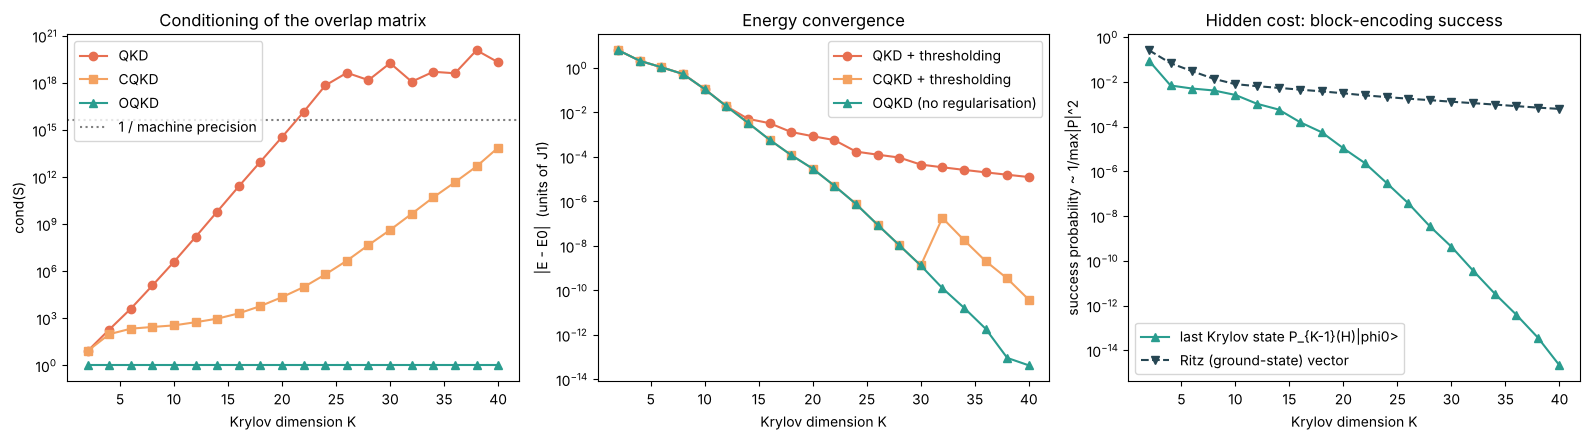

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
col = {"QKD": "#e76f51", "CQKD": "#f4a261", "OQKD": "#2a9d8f"}
for name, m in [("QKD", "o"), ("CQKD", "s"), ("OQKD", "^")]:
    ax[0].semilogy(K_list, cnd[name], marker=m, color=col[name], label=name)
ax[0].axhline(1 / np.finfo(float).eps, ls=":", c="gray", label="1 / machine precision")
ax[0].set(xlabel="Krylov dimension K", ylabel="cond(S)", title="Conditioning of the overlap matrix")
ax[0].legend()
for name, lab, m in [("QKD+thr", "QKD + thresholding", "o"), ("CQKD+thr", "CQKD + thresholding", "s"),
                     ("OQKD", "OQKD (no regularisation)", "^")]:
    err = np.maximum(np.abs(np.array(res[name]) - E0), 1e-15)
    ax[1].semilogy(K_list, err, marker=m, color=col[name.split("+")[0]], label=lab)
ax[1].set(xlabel="Krylov dimension K", ylabel="|E - E0|  (units of J1)", title="Energy convergence")
ax[1].legend()
ax[2].semilogy(K_list, succ, "^-", color=col["OQKD"], label="last Krylov state P_{K-1}(H)|phi0>")
ax[2].semilogy(K_list, succ_ritz, "v--", color="#264653", label="Ritz (ground-state) vector")
ax[2].set(xlabel="Krylov dimension K", ylabel="success probability ~ 1/max|P|^2",
          title="Hidden cost: block-encoding success")
ax[2].legend()
plt.tight_layout(); plt.savefig("q004_stability.png", dpi=110); plt.show()

## 5. Pitfall: the naive rescaling H/λ
The natural block-encoding normalisation is the LCU 1-norm λ. Here it squeezes the spectrum into [−0.38, 0.33]. The Lanczos polynomials then have to be steep on that small interval, so they grow enormously on the rest of [−1, 1]. Rounding errors amplified by those huge coefficients destroy orthogonality.

In [8]:
Ht_naive = rescaled(0.0, lam)
print("OQKD with the naive rescaling H / lambda (spectrum squeezed into [-0.38, 0.33]):")
for K in [8, 16, 20, 24, 30]:
    out = oqkd(phi0, K, Ht_naive, 0.0, lam)
    mx = np.max(np.abs(C.chebval(xs, out["polys"][-1])))
    print(f"  K={K:2d}: steps run {len(out['polys']):2d},  error {out['E']-E0:+9.2e},  "
          f"max|S-I| = {out['orth']:.1e},  max|P| = {mx:.1e}")

OQKD with the naive rescaling H / lambda (spectrum squeezed into [-0.38, 0.33]):
  K= 8: steps run  8,  error +5.36e-01,  max|S-I| = 1.6e-12,  max|P| = 2.3e+05
  K=16: steps run 16,  error +5.96e-04,  max|S-I| = 5.5e-06,  max|P| = 3.0e+11
  K=20: steps run 20,  error +2.97e-05,  max|S-I| = 9.6e-03,  max|P| = 3.2e+14
  K=24: steps run 23,  error -2.65e+01,  max|S-I| = 4.4e+00,  max|P| = 6.0e+16
  K=30: steps run 23,  error -2.65e+01,  max|S-I| = 4.4e+00,  max|P| = 6.0e+16


## 6. Restarted OQKD
Run K_r Lanczos steps, take the lowest Ritz vector Q(H)|start⟩ as the new starting state, and repeat. Each circuit then contains a polynomial of degree at most K_r − 1. We track two success probabilities: preparing the **restarted state** (the chain of Ritz filters, which is the state you would hand to phase estimation), and preparing the **last Krylov state measured** in each cycle.

In [9]:
def restarted_oqkd(K_r, cycles, noise=0.0, seed=0):
    """Run OQKD for K_r steps, restart from the lowest Ritz vector, repeat."""
    rng = np.random.default_rng(seed)
    start, history, cumulative = phi0.copy(), [], 1.0
    for cyc in range(cycles):
        out = oqkd(start, K_r, Ht, shift, scale, noise, rng)
        y, polys = out["y"], out["polys"]
        L = max(len(p) for p in polys)
        Q = sum(yi * np.pad(p, (0, L - len(p))) for yi, p in zip(y, polys))   # Ritz polynomial
        new = out["V"][:, :len(y)] @ y
        p_stage = np.linalg.norm(new) ** 2 / np.max(np.abs(C.chebval(xs, Q))) ** 2
        p_inner = 1 / np.max(np.abs(C.chebval(xs, polys[-1]))) ** 2   # last Krylov state this cycle
        p_measure = cumulative * p_inner        # preparing that state = earlier filters + P_n
        cumulative *= p_stage                   # chain of Ritz filters = the restarted state itself
        start = new / np.linalg.norm(new)
        history.append((cyc + 1, (cyc + 1) * (K_r - 1), out["E"] - E0, cumulative, p_measure))
    return history

restart_runs = {}
for K_r in [4, 6, 8]:
    restart_runs[K_r] = restarted_oqkd(K_r, 12)
    print(f"Restart every K_r = {K_r} steps")
    for cyc, deg, err, p, p_tot in restart_runs[K_r][1::2]:
        print(f"   cycle {cyc:2d} (total degree {deg:2d}):  error {err:9.2e},  "
              f"success: restarted state {p:.1e},  last measured Krylov state {p_tot:.1e}")

Restart every K_r = 4 steps
   cycle  2 (total degree  6):  error  8.31e-01,  success: restarted state 2.1e-02,  last measured Krylov state 4.6e-04
   cycle  4 (total degree 12):  error  5.89e-02,  success: restarted state 5.3e-03,  last measured Krylov state 7.9e-06
   cycle  6 (total degree 18):  error  3.25e-03,  success: restarted state 2.7e-03,  last measured Krylov state 2.4e-07
   cycle  8 (total degree 24):  error  1.88e-04,  success: restarted state 1.4e-03,  last measured Krylov state 7.0e-09
   cycle 10 (total degree 30):  error  1.13e-05,  success: restarted state 7.1e-04,  last measured Krylov state 2.1e-10
   cycle 12 (total degree 36):  error  6.92e-07,  success: restarted state 3.6e-04,  last measured Krylov state 6.5e-12
Restart every K_r = 6 steps
   cycle  2 (total degree 10):  error  6.51e-02,  success: restarted state 7.3e-03,  last measured Krylov state 3.6e-05
   cycle  4 (total degree 20):  error  1.31e-04,  success: restarted state 2.9e-03,  last measured Krylo

## 7. Shot noise
Every measured ⟨H⟩ and ⟨H²⟩ gets Gaussian noise of standard deviation ε (rescaled units; ε ≈ 1/√shots). Each noise level is averaged over 20 random seeds.

In [10]:
noise_levels = [1e-8, 1e-6, 1e-5, 1e-4, 1e-3]
seeds = range(20)
noise_plain, noise_restart = [], []
print("Gaussian noise on every measured <H> and <H^2>  (rescaled units, ~ 1/sqrt(shots))")
for eps in noise_levels:
    plain = np.array([oqkd(phi0, 30, Ht, shift, scale, eps, np.random.default_rng(s))["E"] - E0
                      for s in seeds])
    rest = np.array([restarted_oqkd(6, 8, eps, s)[-1][2] for s in seeds])
    noise_plain.append(plain); noise_restart.append(rest)
    print(f"noise {eps:6.0e} (~{eps**-2:7.0e} shots):  OQKD K=30 median|err| {np.median(np.abs(plain)):8.1e}"
          f" (worst {plain.min():+8.1e})   restarted 6x8 median|err| {np.median(np.abs(rest)):8.1e}"
          f" (worst {rest.min():+8.1e})")

Gaussian noise on every measured <H> and <H^2>  (rescaled units, ~ 1/sqrt(shots))


noise  1e-08 (~  1e+16 shots):  OQKD K=30 median|err|  1.0e-08 (worst -2.8e-08)   restarted 6x8 median|err|  2.8e-07 (worst -4.1e-07)


noise  1e-06 (~  1e+12 shots):  OQKD K=30 median|err|  1.2e-06 (worst -2.9e-06)   restarted 6x8 median|err|  2.1e-05 (worst -3.8e-05)


noise  1e-05 (~  1e+10 shots):  OQKD K=30 median|err|  1.2e-05 (worst -2.9e-05)   restarted 6x8 median|err|  3.0e-04 (worst -5.1e-01)


noise  1e-04 (~  1e+08 shots):  OQKD K=30 median|err|  1.2e-04 (worst -2.8e-04)   restarted 6x8 median|err|  9.7e-04 (worst -1.1e+01)


noise  1e-03 (~  1e+06 shots):  OQKD K=30 median|err|  1.2e-03 (worst -8.0e+00)   restarted 6x8 median|err|  1.3e-02 (worst -1.1e+01)


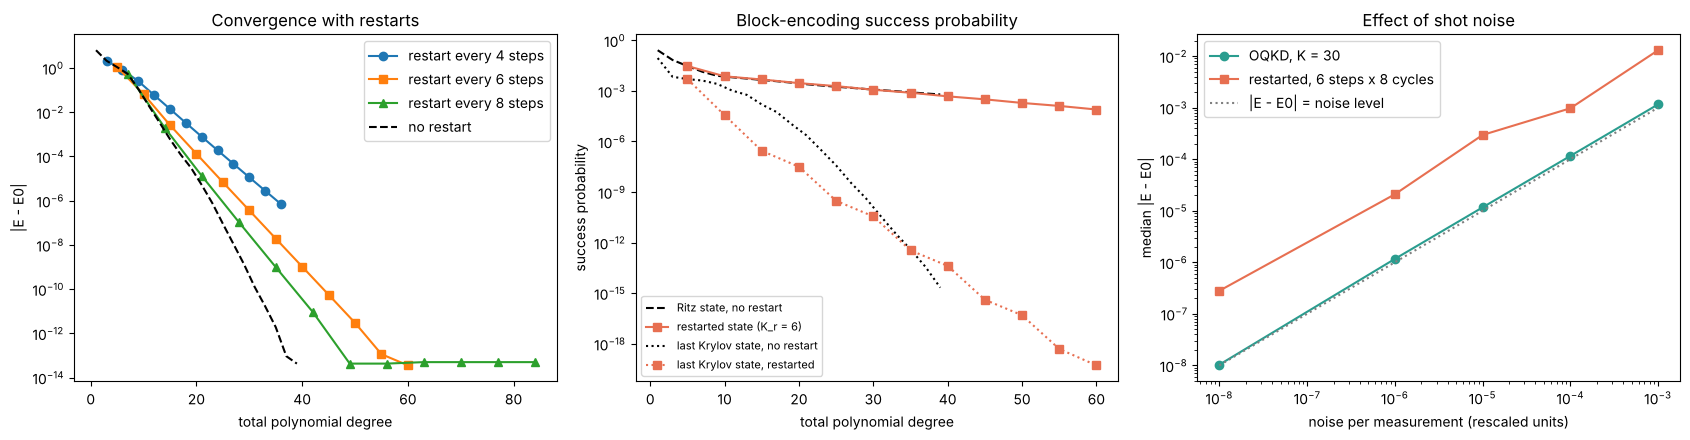

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
deg_plain = [K - 1 for K in K_list]
for K_r, m in [(4, "o"), (6, "s"), (8, "^")]:
    h = restart_runs[K_r]
    ax[0].semilogy([x[1] for x in h], [max(abs(x[2]), 1e-15) for x in h], marker=m,
                   label=f"restart every {K_r} steps")
ax[0].semilogy(deg_plain, np.maximum(np.abs(np.array(res["OQKD"]) - E0), 1e-15), "k--", label="no restart")
ax[0].set(xlabel="total polynomial degree", ylabel="|E - E0|", title="Convergence with restarts")
ax[0].legend()

h = restart_runs[6]
ax[1].semilogy(deg_plain, succ_ritz, "k--", label="Ritz state, no restart")
ax[1].semilogy([x[1] for x in h], [x[3] for x in h], "s-", color="#e76f51", label="restarted state (K_r = 6)")
ax[1].semilogy(deg_plain, succ, "k:", label="last Krylov state, no restart")
ax[1].semilogy([x[1] for x in h], [x[4] for x in h], "s:", color="#e76f51",
               label="last Krylov state, restarted")
ax[1].set(xlabel="total polynomial degree", ylabel="success probability",
          title="Block-encoding success probability")
ax[1].legend(fontsize=8)

eps_arr = np.array(noise_levels)
ax[2].loglog(eps_arr, [np.median(np.abs(x)) for x in noise_plain], "o-", color="#2a9d8f", label="OQKD, K = 30")
ax[2].loglog(eps_arr, [np.median(np.abs(x)) for x in noise_restart], "s-", color="#e76f51",
             label="restarted, 6 steps x 8 cycles")
ax[2].loglog(eps_arr, eps_arr, ":", c="gray", label="|E - E0| = noise level")
ax[2].set(xlabel="noise per measurement (rescaled units)", ylabel="median |E - E0|",
          title="Effect of shot noise")
ax[2].legend()
plt.tight_layout(); plt.savefig("q004_restart_noise.png", dpi=110); plt.show()

## Solution and discussion

**1. QKD and CQKD are ill-conditioned.** cond(S) grows exponentially for the power basis and passes 1/machine precision near K ≈ 22, after which the plain generalised eigenproblem fails (`nan`). Thresholding keeps it running but **stalls convergence at about 10⁻⁵**. The Chebyshev basis is much better conditioned and, with tight rescaling, converges well, but cond(S) still grows to about 10¹⁴ by K = 40.

**2. OQKD is orthogonal by construction.** cond(S) = 1.00 at every K, max|S − I| stays below about 10⁻⁹, and the energy converges exactly like classical Lanczos down to **about 10⁻¹⁴**, with no regularisation. This reproduces the paper's central claim.

**3. The hidden cost is success probability.** The orthogonal Krylov states Pₙ(H)|Φ₀⟩ point along ever smaller *residual* directions, so their polynomials must be large on [−1, 1]. The block-encoding success probability of the last Krylov state falls exponentially, from about 10⁻² at K = 4 to about 10⁻¹⁵ at K = 40. The **Ritz (ground-state) vector** is far cheaper, at about 10⁻³. OQKD swaps the classical *ill-conditioning* problem for a quantum *post-selection* problem.

**4. Rescaling is essential.** With the naive H/λ scaling, orthogonality degrades to about 10⁻² by K = 20 and the method breaks down at K ≈ 23 with a nonsense energy. With a tight spectral rescaling it is stable to K = 40. On hardware this requires good spectral bounds, which the shift and scale in the block encoding must provide.

**5. Restarting** keeps each circuit's polynomial degree small (≤ K_r − 1) and still converges to machine precision. The restarted state's success probability stays affordable (about 10⁻³ to 10⁻⁴), similar to the unrestarted Ritz vector. In this emulation, however, the **Krylov states that have to be measured** late in the run remain exponentially unlikely to prepare, with or without restarts, because they lie along tiny residual directions.

**6. Shot noise.** For plain OQKD, the energy error is almost exactly **equal to the noise level** per measurement: errors don't blow up through the recursion over 30 steps. At larger noise (10⁻³), occasional runs give badly wrong, *below-E₀* energies, because OQKD is not variational once the coefficients are noisy. Restarting multiplies the number of measurements, which makes the noise sensitivity about 10–20× worse.

**Takeaway:** OQKD removes the overlap-matrix instability and needs no thresholding, but it needs accurate spectral rescaling and pays in block-encoding success probability. Those two costs decide whether it beats Chebyshev QKD on a real fault-tolerant device.

*Caveats:* this is a 12-qubit statevector emulation. The success probability is estimated as 1/max|P|² (the GQSP normalisation), without amplitude amplification. The noise model is simple Gaussian noise on ⟨H⟩ and ⟨H²⟩, and the paper's own resource analysis may differ.